# PS3: **Logistic Regression**

### Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn import metrics
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

## Load the Dataset

In [2]:
data = pd.read_csv('mushrooms.csv')
pd.set_option('display.max_columns', None)

In [3]:
data.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


In [4]:
data.tail()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
8119,e,k,s,n,f,n,a,c,b,y,e,?,s,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,e,?,s,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,e,?,s,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,t,?,s,k,w,w,p,w,o,e,w,v,l
8123,e,x,s,n,f,n,a,c,b,y,e,?,s,s,o,o,p,o,o,p,o,c,l


In [5]:
data.shape

(8124, 23)

In [6]:
print("Number of rows: ", data.shape[0])
print("Number of columns: ", data.shape[1])

Number of rows:  8124
Number of columns:  23


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

##### **Check for null values**

In [8]:
data.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [9]:
data.describe()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,2,5,4,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,t,b,s,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,4608,3776,5176,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


##### **Convert from object to categorical data type**

In [10]:
data = data.astype('category')

In [11]:
data.dtypes

class                       category
cap-shape                   category
cap-surface                 category
cap-color                   category
bruises                     category
odor                        category
gill-attachment             category
gill-spacing                category
gill-size                   category
gill-color                  category
stalk-shape                 category
stalk-root                  category
stalk-surface-above-ring    category
stalk-surface-below-ring    category
stalk-color-above-ring      category
stalk-color-below-ring      category
veil-type                   category
veil-color                  category
ring-number                 category
ring-type                   category
spore-print-color           category
population                  category
habitat                     category
dtype: object

##### **Convert categorical values into numerical values**

In [12]:
le = LabelEncoder()
for column in data.columns:
    data[column] = le.fit_transform(data[column])

##### **Store features in X and target in y**

In [13]:
X = data.drop('class', axis=1)
y = data['class']

##### **Application of Principal Component Analysis (PCA)**
    The Dataset contains 22 features, which is quite high. This removes the highly correlated columns so that dataset becomes smaller in size and still holds most of the information.
 This is to reduce the dimensionality of the data.
 The idea of this is simple, reduce the number of variables in the dataset while still preserving as much information as possible.

In [14]:
pca = PCA(n_components=7)
pca_fit = pca.fit_transform(X)

In [15]:
pca.explained_variance_ratio_

array([0.33758733, 0.16581098, 0.12285821, 0.06796611, 0.05831173,
       0.05092539, 0.04670841])

##### **Retained information after PCA**
After applying PCA, we can see that 7 components retained 85% of information of the original data.

In [16]:
sum(pca.explained_variance_ratio_)

np.float64(0.8501681635086222)

## Splitting Data into Training and Test Sets

In [17]:
X_train, X_test, y_train, y_test = train_test_split(pca_fit, y, test_size=0.2, random_state=42)

In [18]:
X_train, y_train

(array([[-7.11666079, -2.04335194, -0.58359556, ..., -1.90182908,
         -0.80613229, -0.02418544],
        [-6.17595898,  1.68576215,  0.9681486 , ...,  2.80668203,
          0.42722726,  2.5694384 ],
        [-7.57107815, -2.4073196 , -0.16605645, ..., -0.82338229,
         -0.78361228, -1.11643962],
        ...,
        [ 4.85510949, -2.15771305,  2.09313421, ...,  3.45422793,
         -0.59087521, -0.72302028],
        [-6.37808881,  0.67611882, -0.90648857, ...,  3.50431296,
         -1.01042037,  1.0942072 ],
        [-3.64709333, -1.66274146,  1.21426462, ..., -0.11997884,
         -1.44771523,  0.65846372]], shape=(6499, 7)),
 7873    1
 6515    1
 6141    1
 2764    0
 438     0
        ..
 5226    1
 5390    0
 860     0
 7603    1
 7270    0
 Name: class, Length: 6499, dtype: int64)

## Standardize the Data


In [19]:
scaler = StandardScaler()

# Fit on training set only.
scaler.fit(X_train)

# Apply transform to both the training set and the test set.
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

## Logistic Regression

In [20]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [21]:
# One test observation (its 7 PCA components) after standardization
X_test[0].reshape(1,-1)

array([[-0.49111639,  0.07456228,  0.41299806, -0.90874537, -0.46051598,
         0.5308426 , -2.00016142]])

In [22]:
print('prediction', model.predict(X_test[0].reshape(1,-1))[0])
print('probability', model.predict_proba(X_test[0].reshape(1,-1)))

prediction 0
probability [[0.67058493 0.32941507]]


In [23]:
# Create DataFrame with proper structure
example_df = pd.DataFrame({
    'features': X_test[:, 0],  # Use first PCA component for visualization
    'class': y_test,
    'logistic_preds': model.predict_proba(X_test)[:, 1]  # Get probability of class 1
})

In [24]:
example_df.head()

,features,class,logistic_preds
1971,-0.491116,0,0.329415
6654,-1.773943,1,0.785491
5606,-1.420999,1,0.962022
3332,0.204099,0,0.467733
6988,-1.724328,1,0.830987


## Visualization

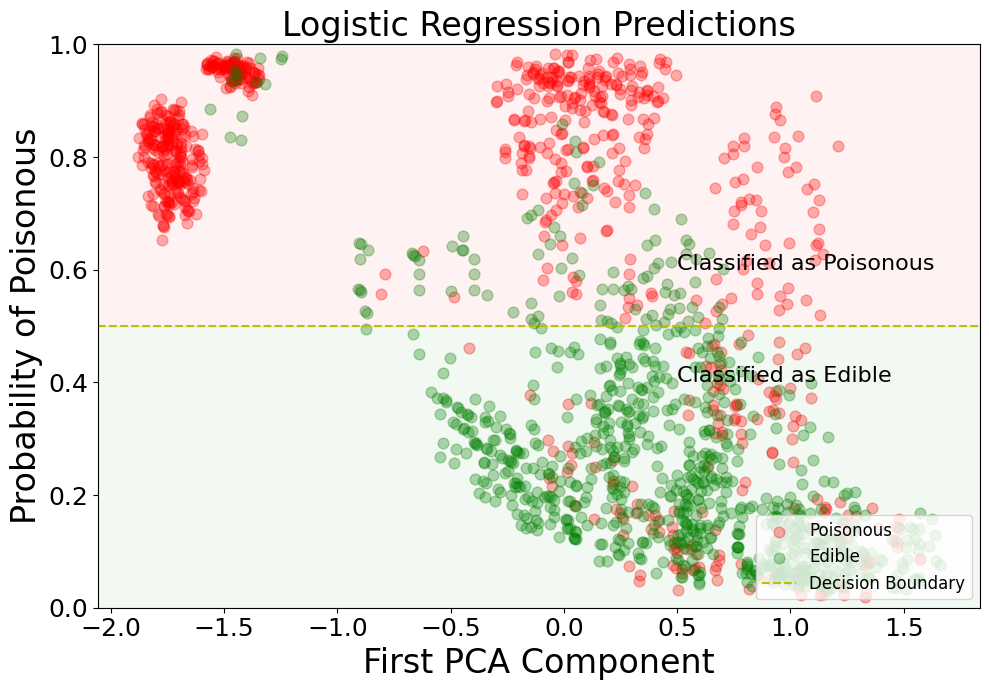

In [37]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10,7))

# Filter for poisonous and edible mushrooms
poisonous_filter = example_df['class'] == 1
edible_filter = example_df['class'] == 0

# Plot poisonous mushrooms
ax.scatter(example_df.loc[poisonous_filter, 'features'],
          example_df.loc[poisonous_filter, 'logistic_preds'],
          color='r',
          s=60,
          alpha=0.3,  # Add some transparency
          label='Poisonous')

# Plot edible mushrooms  
ax.scatter(example_df.loc[edible_filter, 'features'],
          example_df.loc[edible_filter, 'logistic_preds'],
          color='g',
          s=60,
          alpha=0.3,  # Add some transparency
          label='Edible')

# Add the logistic regression curve
x_range = np.linspace(example_df['features'].min(), example_df['features'].max(), 300)
X_range_reshaped = np.zeros((len(x_range), X_test.shape[1]))
X_range_reshaped[:, 0] = x_range  # Set first PCA component
y_proba = model.predict_proba(X_range_reshaped)[:, 1]

# Add decision boundary line
ax.axhline(y=0.5, c='y', linestyle='--', label='Decision Boundary')

# Add shaded regions
ax.axhspan(0.5, 1, alpha=0.05, color='red')
ax.axhspan(0, 0.4999, alpha=0.05, color='green')
ax.text(0.5, 0.6, 'Classified as Poisonous', fontsize=16)
ax.text(0.5, 0.4, 'Classified as Edible', fontsize=16)

# Customize the plot
ax.set_ylim(0, 1)
ax.legend(loc='lower right', markerscale=1.0, fontsize=12)
ax.tick_params(labelsize=18)
ax.set_xlabel('First PCA Component', fontsize=24)  # Updated label
ax.set_ylabel('Probability of Poisonous', fontsize=24)
ax.set_title('Logistic Regression Predictions', fontsize=24)
fig.tight_layout()
plt.show()

## Measuring Model Performance

In [26]:
score = model.score(X_test, y_test)
print(score)

0.8344615384615385


In [27]:
#Predicting the Test set results
y_pred = model.predict(X_test)

In [28]:
print ("ACC LR", accuracy_score(y_test, y_pred))

ACC LR 0.8344615384615385


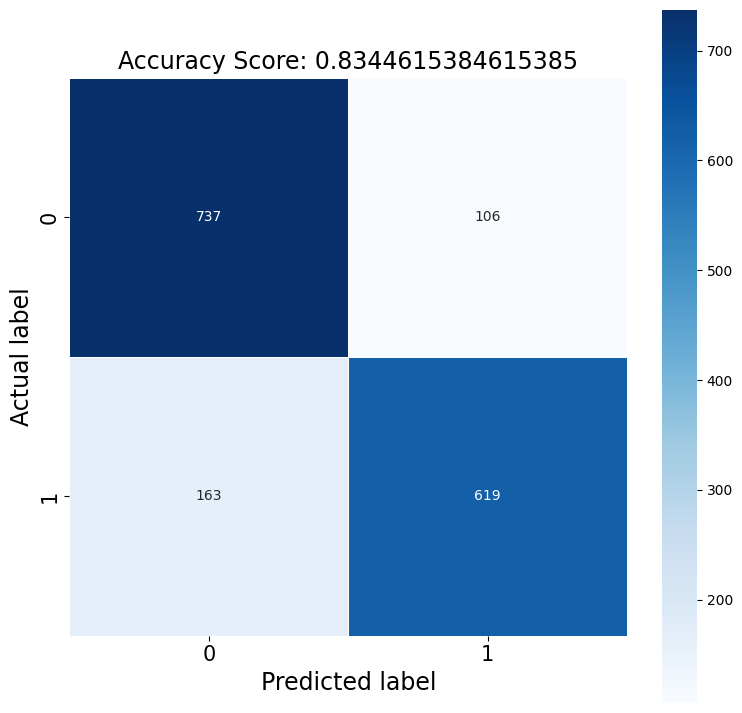

In [29]:
cm = metrics.confusion_matrix(y_test, model.predict(X_test))

plt.figure(figsize=(9,9))
sns.heatmap(cm, annot=True,
            fmt=".0f",
            linewidths=.5,
            square = True,
            cmap = 'Blues');
plt.ylabel('Actual label', fontsize = 17);
plt.xlabel('Predicted label', fontsize = 17);
plt.title('Accuracy Score: {}'.format(score), size = 17);
plt.tick_params(labelsize= 15)

## Applying L1 Regularization

In [30]:
l1_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.5)
l1_model.fit(X_train, y_train)

y_pred_l1 = l1_model.predict(X_test)

## Applying L2 Regularization

In [35]:
l2_model = LogisticRegression(penalty='l2', C=0.5)
l2_model.fit(X_train, y_train)

y_pred_l2 = l2_model.predict(X_test)

## Comparing Models Accuracy

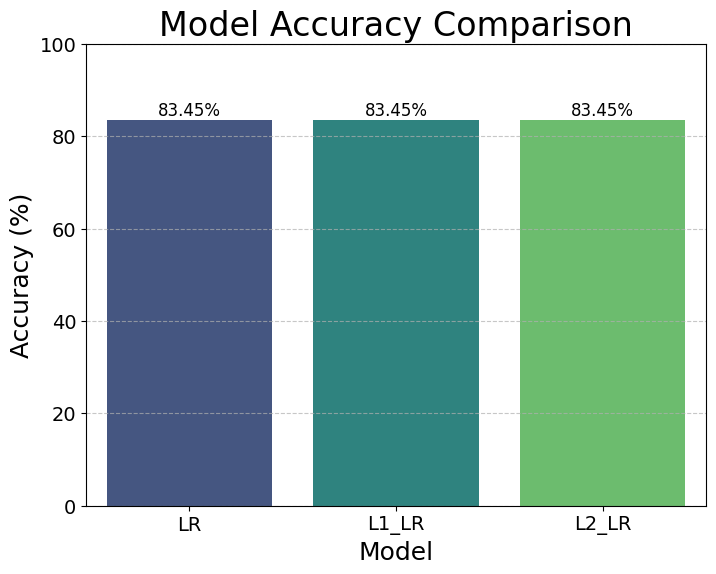

In [41]:
accuracy_df = pd.DataFrame({
    'Model': ['LR', 'L1_LR', 'L2_LR'],
    'Accuracy': [accuracy_score(y_test, y_pred) * 100,
                 accuracy_score(y_test, y_pred_l1) * 100,
                 accuracy_score(y_test, y_pred_l2) * 100]
})

# Visualization of model accuracy
plt.figure(figsize=(8, 6))
sns.barplot(x='Model', y='Accuracy', hue='Model', data=accuracy_df, palette='viridis', legend=False)
plt.ylim(0, 100)  # Set y-axis limits to 0-100%
plt.title('Model Accuracy Comparison', fontsize=24)
plt.xlabel('Model', fontsize=18)
plt.ylabel('Accuracy (%)', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding accuracy text at the top of each bar
for index, value in enumerate(accuracy_df['Accuracy']):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center', fontsize=12)

plt.show()